In [ ]:
!pip install -U datasets transformers evaluate accelerate tdqm nltk sentencepiece rouge_score gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/54.3 MB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.9/323.9 kB 31.6 MB/s eta 0:00:00
  Attempting uninstall: gradio-client
    Found existing installation: gradio_client 1.10.1
    Uninstalling gradio_client-1.10.1:
      Successfully uninstalled gradio_client-1.10.1
  Attempting uninstall: gradio
    Found existing installation: gradio 5.31.0
    Uninstalling gradio-5.31.0:
      Successfully uninstalled gradio-5.31.0


### Summarization
Text Summarization is the task of condensing long documents into summaries. This is one of the most challenging NLP tasks as it requires a range of abilities, such as understanding long passages and generating coherent text that captures the main topics in a document. However, when done well, text summarization is a powerful tool that can speed up various business processes by relieving the burden of domain experts to read long documents in detail.

Although there already exist various fine-tuned models for summarization on the Hugging Face Hub, almost all of these are only suitable for English documents. So, to add a twist, we’ll train a bilingual model for English and Spanish.

As we’ll see, these summaries are concise because they’re learned from the titles that customers provide in their product reviews. Let’s start by putting together a suitable bilingual corpus for this task.

### 1. Load the data


#### Preparing a multilingual corpus
We are using the Multilingual Amazon Reviews Corpus to create our bilingual summarizer. This corpus consists of Amazon product reviews in six languages and is typically used to benchmark multilingual classifiers. However, since each review is accompanied by a short title, we can use the titles as the target summaries for our model to learn from! To get started, let’s download the English and Spanish subsets from the Hugging Face Hub.

In [ ]:
# from datasets import load_dataset

# spanish_dataset = load_dataset("amazon_reviews_multi", "es") # 200000, 5000, 5000
# english_dataset = load_dataset("amazon_reviews_multi", "en") # 200000, 5000, 5000

# Not working anymore as amazon decided to make it not accessible.

In [ ]:
# Download the dataset from kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mexwell/amazon-reviews-multi")

print("Path to dataset files:", path)

100%|██████████| 131M/131M [00:00<00:00, 172MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/mexwell/amazon-reviews-multi/versions/1


In [ ]:
# Convert the Kaggle csv dataset with different splits to Huggingface dataset

from datasets import load_dataset

ds = load_dataset("csv", data_files={
    "train": "/root/.cache/kagglehub/datasets/mexwell/amazon-reviews-multi/versions/1/train.csv",
    "validation": "/root/.cache/kagglehub/datasets/mexwell/amazon-reviews-multi/versions/1/validation.csv",
    "test": "/root/.cache/kagglehub/datasets/mexwell/amazon-reviews-multi/versions/1/validation.csv",
})

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 1200000
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 30000
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 30000
    })
})

In [ ]:
ds["train"].features

{'Unnamed: 0': Value(dtype='int64', id=None),
 'review_id': Value(dtype='string', id=None),
 'product_id': Value(dtype='string', id=None),
 'reviewer_id': Value(dtype='string', id=None),
 'stars': Value(dtype='int64', id=None),
 'review_body': Value(dtype='string', id=None),
 'review_title': Value(dtype='string', id=None),
 'language': Value(dtype='string', id=None),
 'product_category': Value(dtype='string', id=None)}

In [ ]:
ds["train"][0]

{'Unnamed: 0': 0,
 'review_id': 'de_0203609',
 'product_id': 'product_de_0865382',
 'reviewer_id': 'reviewer_de_0267719',
 'stars': 1,
 'review_body': 'Armband ist leider nach 1 Jahr kaputt gegangen',
 'review_title': 'Leider nach 1 Jahr kaputt',
 'language': 'de',
 'product_category': 'sports'}

In [ ]:
ds["train"].unique("language")  # unique languages

['de', 'en', 'es', 'fr', 'ja', 'zh']

In [ ]:
len(ds["train"].unique("review_id"))

1200000

In [ ]:
# Prepare the English and Spanish Datasets using filer

en_ds = {split: ds[split].filter(lambda x: x["language"] == "en") for split in ds}  # English
es_ds = {split: ds[split].filter(lambda x: x["language"] == "es") for split in ds}  # Spanish

Filter:   0%|          | 0/1200000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/30000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/30000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1200000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/30000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/30000 [00:00<?, ? examples/s]

In [ ]:
en_ds

{'train': Dataset({
     features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
     num_rows: 200000
 }),
 'validation': Dataset({
     features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
     num_rows: 5000
 }),
 'test': Dataset({
     features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
     num_rows: 5000
 })}

In [ ]:
es_ds

{'train': Dataset({
     features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
     num_rows: 200000
 }),
 'validation': Dataset({
     features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
     num_rows: 5000
 }),
 'test': Dataset({
     features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
     num_rows: 5000
 })}

In [ ]:
from datasets import DatasetDict

eng_ds = DatasetDict(en_ds) # English
esp_ds = DatasetDict(es_ds) # Espanol

In [ ]:
eng_ds

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
})

In [ ]:
esp_ds

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
})

For each language there are 200,000 reviews for the train split, and 5,000 reviews for each of the validation and test splits. The review information we are interested is contained in the `review_body` and `review_title` columns.

Let’s take a look at a few examples by creating a simple function that takes a random sample from the training set.

In [ ]:
def show_samples(dataset, num_samples=3, seed=42):
    samples = dataset["train"].shuffle(seed=seed).select(range(num_samples))
    for example in samples:
        print(f"\n'>>Title: {example['review_title']}")
        print(f"'>>Review: {example['review_body']}")

In [ ]:
show_samples(eng_ds)


'>>Title: Worked in front position, not rear
'>>Review: 3 stars because these are not rear brakes as stated in the item description. At least the mount adapter only worked on the front fork of the bike that I got it for.

'>>Title: meh
'>>Review: Does it’s job and it’s gorgeous but mine is falling apart, I had to basically put it together again with hot glue

'>>Title: Can't beat these for the money
'>>Review: Bought this for handling miscellaneous aircraft parts and hanger "stuff" that I needed to organize; it really fit the bill. The unit arrived quickly, was well packaged and arrived intact (always a good sign). There are five wall mounts-- three on the top and two on the bottom. I wanted to mount it on the wall, so all I had to do was to remove the top two layers of plastic drawers, as well as the bottom corner drawers, place it when I wanted and mark it; I then used some of the new plastic screw in wall anchors (the 50 pound variety) and it easily mounted to the wall. Some have r

In [ ]:
show_samples(esp_ds)


'>>Title: .
'>>Review: La montarlo se rompió una rueda debido a materiales débiles, pero al arreglarla funciona correctamente.

'>>Title: Primeras impresiones
'>>Review: El servicio ha sido muy bueno, me ha llegado 2 días antes de lo previsto. En cuanto al producto no es que me haya dado muy buenas primeras impresiones. El borde del protector es de plástico y lo único que hay de cristal es la pantalla. Además el plástico es muy fino. A nivel estético queda muy bien y se ajusta perfectamente, la única queja que tengo es eso, que no sea todo de cristal y que para mi gusto es demasiado fino. De la resistencia no tengo ni idea ya que es el primer día que lo llevo. No creo que sea mal producto del todo si no que depende del gusto y el cuidado que tenga cada uno de su móvil. Personalmente creo que por el mismo precio hay otros productos que si que son enteros de cristal y más gordos que por lo menos a mí me generan más confianza.

'>>Title: .
'>>Review: Funciona genial y la llevo conmigo en

This sample shows the diversity of reviews one typically finds online, ranging from positive to negative (and everything in between!). Although the example with the “meh” title is not very informative, the other titles look like decent summaries of the reviews themselves.

Training a summarization model on all combined 400,000 reviews would take far too long on a single GPU, so instead let's focus on generating summaries for a single domain of products.

To get a feel for what domains we can choose from, let’s convert `eng_ds` to a `pandas.DataFrame` and compute the number of reviews per `product_category`.

In [ ]:
eng_ds.set_format("pandas") # set format to pandas

eng_df = eng_ds["train"][:] # Get the train dataset

eng_df.head()

,Unnamed: 0,review_id,product_id,reviewer_id,stars,review_body,review_title,language,product_category
0,200000,en_0964290,product_en_0740675,reviewer_en_0342986,1,Arrived broken. Manufacturer defect. Two of th...,I'll spend twice the amount of time boxing up ...,en,furniture
1,200001,en_0690095,product_en_0440378,reviewer_en_0133349,1,the cabinet dot were all detached from backing...,Not use able,en,home_improvement
2,200002,en_0311558,product_en_0399702,reviewer_en_0152034,1,I received my first order of this product and ...,The product is junk.,en,home
3,200003,en_0044972,product_en_0444063,reviewer_en_0656967,1,This product is a piece of shit. Do not buy. D...,Fucking waste of money,en,wireless
4,200004,en_0784379,product_en_0139353,reviewer_en_0757638,1,went through 3 in one day doesn't fit correct ...,bubble,en,pc


In [ ]:
eng_df["product_category"].value_counts()

,count
product_category,
home,17679
apparel,15951
wireless,15717
other,13418
beauty,12091
drugstore,11730
kitchen,10382
toy,8745
sports,8277


In [ ]:
# Show counts for top 20 products
eng_df["product_category"].value_counts()[:20]

,count
product_category,
home,17679
apparel,15951
wireless,15717
other,13418
beauty,12091
drugstore,11730
kitchen,10382
toy,8745
sports,8277


In [ ]:
eng_df["stars"].value_counts() # equally distributed reviews

,count
stars,
1,40000
2,40000
3,40000
4,40000
5,40000


In [ ]:
esp_ds.set_format("pandas") # set format to pandas

esp_df = esp_ds["train"][:] # Get the train dataset

esp_df.head()

,Unnamed: 0,review_id,product_id,reviewer_id,stars,review_body,review_title,language,product_category
0,400000,es_0491108,product_es_0296024,reviewer_es_0999081,1,Nada bueno se me fue ka pantalla en menos de 8...,television Nevir,es,electronics
1,400001,es_0869872,product_es_0922286,reviewer_es_0216771,1,"Horrible, nos tuvimos que comprar otro porque ...",Dinero tirado a la basura con esta compra,es,electronics
2,400002,es_0811721,product_es_0474543,reviewer_es_0929213,1,Te obligan a comprar dos unidades y te llega s...,solo llega una unidad cuando te obligan a comp...,es,drugstore
3,400003,es_0359921,product_es_0656090,reviewer_es_0224702,1,"No entro en descalificar al vendedor, solo pue...",PRODUCTO NO RECIBIDO.,es,wireless
4,400004,es_0068940,product_es_0662544,reviewer_es_0224827,1,Llega tarde y co la talla equivocada,Devuelto,es,shoes


In [ ]:
esp_df["product_category"].value_counts()

,count
product_category,
home,26962
wireless,25886
toy,13647
sports,13189
pc,11191
home_improvement,10879
electronics,10385
beauty,7337
automotive,7143


In [ ]:
esp_df["product_category"].value_counts()[:20] # top20

,count
product_category,
home,26962
wireless,25886
toy,13647
sports,13189
pc,11191
home_improvement,10879
electronics,10385
beauty,7337
automotive,7143


In [ ]:
esp_df["stars"].value_counts()

,count
stars,
1,40000
2,40000
3,40000
4,40000
5,40000


The most popular products in the English and spanish dataset are about household items, clothing, and wireless electronics. To stick with the Amazon theme, though, let’s focus on summarizing book reviews — after all, this is what the company was founded on!

We can see two product categories that fit the bill (book and digital_ebook_purchase), so let’s filter the datasets in both languages for just these products using `Dataset.filter()`.

In [ ]:
# First reset the format from pandas back to arrow
eng_ds.reset_format()
esp_ds.reset_format()

In [ ]:
def filter_books(example):
    return (example["product_category"] == "book" or example["product_category"] == "digital_ebook_purchase")

In [ ]:
eng_book_reviews = eng_ds.filter(filter_books)
esp_book_reviews = esp_ds.filter(filter_books)

Filter:   0%|          | 0/200000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/200000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

In [ ]:
eng_book_reviews

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 10505
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 231
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 231
    })
})

In [ ]:
esp_book_reviews

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 7107
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 193
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 193
    })
})

In [ ]:
show_samples(eng_book_reviews)


'>>Title: I'm dissapointed.
'>>Review: I guess I had higher expectations for this book from the reviews. I really thought I'd at least like it. The plot idea was great. I loved Ash but, it just didnt go anywhere. Most of the book was about their radio show and talking to callers. I wanted the author to dig deeper so we could really get to know the characters. All we know about Grace is that she is attractive looking, Latino and is kind of a brat. I'm dissapointed.

'>>Title: Good art, good price, poor design
'>>Review: I had gotten the DC Vintage calendar the past two years, but it was on backorder forever this year and I saw they had shrunk the dimensions for no good reason. This one has good art choices but the design has the fold going through the picture, so it's less aesthetically pleasing, especially if you want to keep a picture to hang. For the price, a good calendar

'>>Title: Helpful
'>>Review: Nearly all the tips useful and. I consider myself an intermediate to advanced use

In [ ]:
show_samples(esp_book_reviews)


'>>Title: Regular
'>>Review: Me decepcionó un poco porque no pone que debtro sean imagenes reales, me lo esperaba de otra manera la verdad

'>>Title: Genio entre genios
'>>Review: A sido un gran libro, hay mucho que aprender de este genio

'>>Title: Me esperaba mas
'>>Review: Comparada con otras guías la veo flojita con el precio que tiene. Es muy visual pero echo en falta muchos detalles.


Okay, we can see that the reviews are not strictly about books and might refer to things like calendars and electronic applications such as OneNote. Nevertheless, the domain seems about right to train a summarization model on.  We have one last bit of data preparation to do i.e combining the English and Spanish reviews as a single DatasetDict object.

🤗 Datasets has a handy `concatenate_datasets()` function that will stack two Dataset objects on top of each other. So, to create our bilingual dataset, let's loop over each split, concatenate the datasets for that split, and shuffle the result to ensure our model doesn’t overfit to a single language.

In [ ]:
# Combine both the datasets using hf's concatenate_datasets()
from datasets import concatenate_datasets, DatasetDict

books_ds = DatasetDict()
for split in eng_book_reviews.keys():
    books_ds[split] = concatenate_datasets([eng_book_reviews[split], esp_book_reviews[split]], split=split)
    books_ds[split] = books_ds[split].shuffle(seed=42)

books_ds

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 17612
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 424
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 424
    })
})

In [ ]:
show_samples(books_ds, num_samples=7)


'>>Title: Easy to follow!!!!
'>>Review: I loved The dash diet weight loss Solution. Never hungry. I would recommend this diet. Also the menus are well rounded. Try it. Has lots of the information need thanks.

'>>Title: PARCIALMENTE DAÑADO
'>>Review: Me llegó el día que tocaba, junto a otros libros que pedí, pero la caja llegó en mal estado lo cual dañó las esquinas de los libros porque venían sin protección (forro).

'>>Title: no lo he podido descargar
'>>Review: igual que el anterior

'>>Title: Devoluciones
'>>Review: No he recibido el libro y aún así me lo han cobrado. Ya no lo quiero y no me aparece la opción de devolver. Me gustaría que me devolvieran lo cobrado. Gracias

'>>Title: Todo ok
'>>Review: Buenos y enviado muy pronto

'>>Title: Nothing Special
'>>Review: The storyline left me flat! It started off with a bang, but then got kind of wordy and dull, no twists in the plot line. The ending was disappointing. Lately I have been finding that to be the case with all of the newe

This certainly looks like a mix of English and Spanish reviews! Now that we have a training corpus, one final thing to check is the `distribution of words in the reviews and their titles`.

This is `especially important for summarization tasks, where short reference summaries in the data can bias the model to only output one or two words in the generated summaries`.

In [ ]:
def get_lengths(examples):
    review_lengths = []
    title_lengths = []
    for review, title in zip(examples["review_body"], examples["review_title"]):
        review_lengths.append(len(review.split()))
        title_lengths.append(len(title.split()))
    examples["review_length"] = review_lengths
    examples["title_length"] = title_lengths
    return examples

books_ds = books_ds.map(get_lengths, batched=True)
books_ds

Map:   0%|          | 0/17612 [00:00<?, ? examples/s]

Map:   0%|          | 0/424 [00:00<?, ? examples/s]

Map:   0%|          | 0/424 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category', 'review_length', 'title_length'],
        num_rows: 17612
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category', 'review_length', 'title_length'],
        num_rows: 424
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category', 'review_length', 'title_length'],
        num_rows: 424
    })
})

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_word_distribution(lengths, title):
    plt.figure(figsize=(8, 4))
    plt.hist(lengths, bins=np.arange(0, 20) - 0.5, color="skyblue", edgecolor="black")
    plt.title(f"Word Count Distribution in {title}")
    plt.xlabel("Number of Words")
    plt.ylabel("Frequency")
    plt.xticks(range(0, 20))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

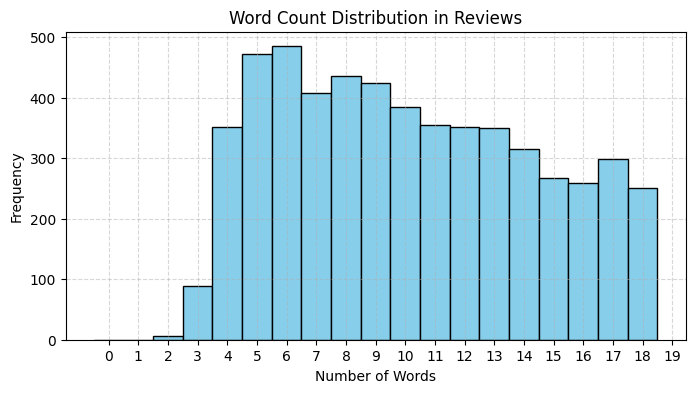

In [ ]:
plot_word_distribution(books_ds["train"]["review_length"], title="Reviews")

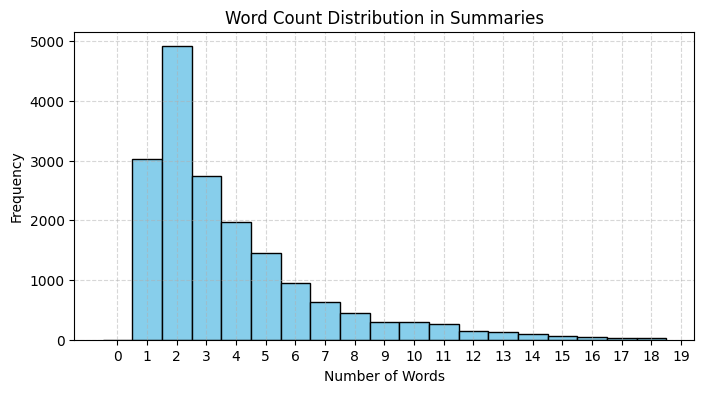

In [ ]:
plot_word_distribution(books_ds["train"]["title_length"], title="Summaries")

The plots below show the word distributions, and we can see that our summeries i.e titles are heavily skewed toward just 1-2 words.

To deal with this, let's filter out the examples with very short titles so that our model can produce more interesting summaries. Since we’re dealing with English and Spanish texts, we can use a rough heuristic to split the titles on whitespace and then use our trusty Dataset.filter() method.

In [ ]:
books_ds = books_ds.filter(lambda x: x["title_length"] > 2)

Filter:   0%|          | 0/17612 [00:00<?, ? examples/s]

Filter:   0%|          | 0/424 [00:00<?, ? examples/s]

Filter:   0%|          | 0/424 [00:00<?, ? examples/s]

In [ ]:
books_ds

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category', 'review_length', 'title_length'],
        num_rows: 9672
    })
    validation: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category', 'review_length', 'title_length'],
        num_rows: 238
    })
    test: Dataset({
        features: ['Unnamed: 0', 'review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category', 'review_length', 'title_length'],
        num_rows: 238
    })
})

### Preprocessing

If you think about it, text summarization is a similar sort of task to machine translation: we have a body of text like a review that we’d like to “translate” into a shorter version that captures the salient features of the input. Accordingly, `most Transformer models for summarization` adopt the `encoder-decoder architecture`, although there are some exceptions like the GPT family of models which can also be used for summarization in few-shot settings.

The majority of Transformer models for summarization (and indeed most NLP tasks) are monolingual. This is great if your task is in a “high-resource” language like English or German, but less so for the thousands of other languages in use across the world. Fortunately, there is a class of multilingual Transformer models, like `mT5 and mBART`, that come to the rescue. These models are pretrained using language modeling, but with a twist: instead of training on a corpus of one language, they are trained jointly on texts in over 50 languages at once!

We’ll use `mT5`, an interesting architecture based on T5 that was `pretrained in a text-to-text framework`. In T5, every NLP task is formulated in terms of a `prompt prefix like summarize, which conditions the model to adapt the generated text to the prompt`. mT5 doesn’t use prefixes, but shares much of the versatility of T5 and has the advantage of being multilingual. Now that we’ve picked a model, let’s prepare our data for training.

Our next task is to `tokenize and encode our reviews and their titles`. As usual, we begin by loading the tokenizer associated with the pretrained model checkpoint. We use `mt5-small` as our checkpoint so we can fine-tune the model in a reasonable amount of time.

Note: we need sentencepiece for this task. So, we need to pip install it. Cuz metric needs sentences for evaluation.

Note: No need to normalize to remove accents(NFD, NFKD) from unicodedata as mt5 tokenizer supports accents.

In [ ]:
from transformers import AutoTokenizer

checkpoint = "google/mt5-small"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
tokenizer

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.11/dist-packages/transformers/convert_slow_tokenizer.py:564: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


T5TokenizerFast(name_or_path='google/mt5-small', vocab_size=250100, model_max_length=1000000000000000019884624838656, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '<pad>'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	0: AddedToken("<pad>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("</s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("<unk>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	250000: AddedToken("▁<extra_id_99>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	250001: AddedToken("▁<extra_id_98>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	250002: AddedToken("▁<extra_id_97>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	250003: Add

In [ ]:
# Test
books_ds["train"][1]["review_body"][:50] # Get 50 chars from first review

'I grew up reading Koontz, and years ago, I stopped'

In [ ]:
# Test
inputs = tokenizer(books_ds["train"][1]["review_body"][:50])
inputs

{'input_ids': [336, 6998, 481, 1150, 11807, 1590, 16339, 360, 261, 305, 3127, 2780, 261, 336, 35042, 345, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [ ]:
tokenizer.convert_ids_to_tokens(inputs["input_ids"])

['▁I',
 '▁gre',
 'w',
 '▁up',
 '▁reading',
 '▁Ko',
 'ont',
 'z',
 ',',
 '▁and',
 '▁years',
 '▁ago',
 ',',
 '▁I',
 '▁stopp',
 'ed',
 '</s>']

In [ ]:
tokenizer.decode(inputs["input_ids"])

'I grew up reading Koontz, and years ago, I stopped</s>'

The special Unicode character `▁`(represents space) and end-of-sequence `</s>` token indicate that we’re dealing with the `SentencePiece tokenizer`, which is based on the `Unigram segmentation algorithm`. Unigram is especially useful for multilingual corpora since it allows SentencePiece to be agnostic about accents, punctuation, and the fact that many languages, like Japanese, do not have whitespace characters.

To tokenize our corpus, we have to deal with a subtlety associated with summarization, because our labels are also text, it is possible that they exceed the model’s maximum context size. This means we need to apply truncation to both the reviews and their titles to ensure we don’t pass excessively long inputs to our model. The tokenizers in 🤗 Transformers provide a nifty `text_target` argument that allows us to tokenize the labels in parallel to the inputs.

In [ ]:
max_target_length = 30
max_input_seq_len = 512

def preprocess(examples):
    inputs = tokenizer(examples["review_body"], max_length=max_input_seq_len, truncation=True)
    labels = tokenizer(examples["review_title"], max_length=max_target_length, truncation=True)
    inputs["labels"] = labels["input_ids"]
    return inputs

tokenized_ds = books_ds.map(preprocess, batched=True, remove_columns=books_ds["train"].column_names)

In [ ]:
tokenized_ds

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 9672
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 238
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 238
    })
})

In [ ]:
len(tokenizer.vocab) # dictionary with vocab word: id

250100

In [ ]:
list(tokenizer.vocab.keys())[:10]

['▁MOL',
 'ទេស',
 '6:11',
 '▁eduka',
 'ᄏ',
 'rial',
 'お答え',
 '▁(128',
 'tibet',
 'æling']

### Metrics for text summarization

In comparison to most of the other tasks in NLP, measuring the performance of text generation tasks like summarization or translation is not as straightforward. For example, given a review like “I loved reading the Hunger Games”, there are multiple valid summaries, like “I loved the Hunger Games” or “Hunger Games is a great read”.

Clearly, applying some sort of exact match (like in QA) between the generated summary and the label is not a good solution, even humans would fare poorly under such a metric, because we all have our own writing style.

For summarization, one of the most commonly used metrics is the `ROUGE` score (short for `Recall-Oriented Understudy for Gisting Evaluation`).

The basic idea behind this metric is to compare a generated summary against a set of reference summaries that are typically created by humans. To make this more precise, suppose we want to compare the following two summaries:

- generated_summary = "I absolutely loved reading the Hunger Games"
- reference_summary = "I loved reading the Hunger Games"

One way to compare them could be to count the `number of overlapping word`, which in this case would be 6. However, this is a bit crude, so instead `ROUGE` is based on computing the `precision and recall scores for the overlap`.

For ROUGE, `recall measures how much of the reference summary is captured by the generated one`. If we are just comparing words, recall can be calculated according to the following formula:

```
Recall = Number of overlapping words / total number of words in reference summary
```
For our simple example above, this formula gives a perfect recall of 6/6 = 1; i.e., all the words in the reference summary have been produced by the model. This may sound great, but imagine if our generated summary had been “I really really loved reading the Hunger Games all night”. This would also have perfect recall, but is arguably a worse summary since it is verbose. To deal with these scenarios we also compute the precision, which in the ROUGE context measures how much of the generated summary was relevant.

```
Precision = Number of overlapping words / total number of words in generated summary
```

Applying this to our verbose summary gives a precision of 6/10 = 0.6, which is considerably worse than the precision of 6/7 = 0.86 obtained by our shorter one.

In practice, `both precision and recall are usually computed, and then the F1-score (the harmonic mean of precision and recall) is reported`. The ROUGE  score is often reported as an F1 score.

We can do this easily in 🤗 Datasets by first installing the `rouge_score` package.

In [ ]:
import evaluate

metric = evaluate.load("rouge")

In [ ]:
reference_summary = "I loved reading the Hunger Games"
generated_summary = "I absolutely loved reading the Hunger Games"

scores = metric.compute(predictions=[generated_summary], references=[reference_summary])
scores

{'rouge1': np.float64(0.923076923076923),
 'rouge2': np.float64(0.7272727272727272),
 'rougeL': np.float64(0.923076923076923),
 'rougeLsum': np.float64(0.923076923076923)}

In [ ]:
reference_summary = "I loved reading the Hunger Games"
generated_summary = "I really really loved reading the Hunger Games all night"

scores = metric.compute(predictions=[generated_summary], references=[reference_summary])
scores

{'rouge1': np.float64(0.7499999999999999),
 'rouge2': np.float64(0.5714285714285714),
 'rougeL': np.float64(0.7499999999999999),
 'rougeLsum': np.float64(0.7499999999999999)}

`rouge2` measures the `overlap between bigrams` (think the overlap of pairs of words), while `rougeL` and `rougeLsum` measure the `longest matching sequences of words by looking for the longest common substrings in the generated and reference summaries`. The “sum” in `rougeLsum` refers to the fact that this metric is `computed over a whole summary`, while `rougeL` is computed as the `average over individual sentences`.

We’ll use these ROUGE scores to track the performance of our model, but before doing that let’s do something every good NLP practitioner should do: `create a strong, yet simple baseline!`

### Create a strong Baseline for text summarization - lead-3 baseline

A common baseline for text summarization is to simply take the `first three sentences of an article`, often called the `lead-3 baseline`.

We could use full stops to track the sentence boundaries, but this will fail on acronyms like “U.S.” or “U.N.” — so instead we’ll use the `nltk` library, which includes a better algorithm to handle these cases.

In [ ]:
import nltk

nltk.download("punkt")  # Punkt is a sentence tokenizer that utilizes an unsupervised machine learning algorithm to identify sentence boundaries in text.
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

Next, we import the `sentence tokenizer` from nltk and create a simple function to `extract the first three sentences in a review`.

The convention in text summarization is to `separate each summary with a newline`, so let’s also include this and test it on a training example.

In [ ]:
books_ds["train"][1]["review_body"]

'I grew up reading Koontz, and years ago, I stopped,convinced i had "outgrown" him. Still,when a friend was looking for something suspenseful too read, I suggested Koontz. She found Strangers. The excitement art how good it was startled me. I was sure i had recommended something else. I ordered a copy for myself. This was a great reintroduction to an old favorite writer -- a novel full of fully developed characters that are totally relatable. People you could care about with full back stories. A mystery that had to be solved. I expected it to be the book I read every few weeks, only on flights. Instead, I\'ve ignored everything and everybody to finish this. Definitely a must read.'

In [ ]:
from nltk.tokenize import sent_tokenize

def three_sentence_summary(text): # generate sumamries directly from the reviews to have a strong baseline
    return "\n".join(sent_tokenize(text)[:3])

print(three_sentence_summary(books_ds["train"][1]["review_body"]))

I grew up reading Koontz, and years ago, I stopped,convinced i had "outgrown" him.
Still,when a friend was looking for something suspenseful too read, I suggested Koontz.
She found Strangers.


Let’s now implement a function that extracts these “summaries” from a dataset and computes the ROUGE scores for the baseline.

In [ ]:
def evaluate_baseline(dataset, metric):
    summaries = [three_sentence_summary(text) for text in dataset["review_body"]]
    return metric.compute(predictions=summaries, references=dataset["review_title"])

In [ ]:
import pandas as pd

results = evaluate_baseline(books_ds["validation"], metric)

In [ ]:
rouge_names = ["rouge1", "rouge2", "rougeL", "rougeLsum"]
rouge_dict = dict((rn, round(results[rn] * 100, 2)) for rn in rouge_names)

rouge_dict

{'rouge1': np.float64(16.81),
 'rouge2': np.float64(8.8),
 'rougeL': np.float64(15.49),
 'rougeLsum': np.float64(15.97)}

We can see that the `rouge2` score is significantly lower than the rest; this likely reflects the fact that review titles are typically concise and so the `lead-3 baseline is too verbose`. Now that we have a good baseline to work from, let’s atRT toward fine-tuning mT5!

We’ll need to generate summaries(as a text rather than numbers) in order to compute ROUGE scores during training. Fortunately, 🤗 Transformers provides dedicated `Seq2SeqTrainingArguments` and `Seq2SeqTrainer` classes that can do this for us automatically!

To see how this works, let’s first define the hyperparameters and other arguments for our experiments.

### Model
Fine-tuning our model with 🤗 Accelerate is very similar to other tasks. The main differences will be the need to explicitly generate our summaries during training and define how we compute the ROUGE scores (recall that the Seq2SeqTrainer took care of the generation for us). Let’s take a look how we can implement these two requirements within 🤗 Accelerate!

Fine-tuning a model for summarization is very similar to the other tasks we’ve covered in this chapter. The first thing we need to do is load the pretrained model from the mt5-small checkpoint. Since summarization is a sequence-to-sequence task, we can load the model with the `AutoModelForSeq2SeqLM` class, which will automatically download and cache the weights.

In [ ]:
from transformers import AutoModelForSeq2SeqLM

model = AutoModelForSeq2SeqLM.from_pretrained(checkpoint) # google/mt5-small

model

pytorch_model.bin:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

MT5ForConditionalGeneration(
  (shared): Embedding(250112, 512)
  (encoder): MT5Stack(
    (embed_tokens): Embedding(250112, 512)
    (block): ModuleList(
      (0): MT5Block(
        (layer): ModuleList(
          (0): MT5LayerSelfAttention(
            (SelfAttention): MT5Attention(
              (q): Linear(in_features=512, out_features=384, bias=False)
              (k): Linear(in_features=512, out_features=384, bias=False)
              (v): Linear(in_features=512, out_features=384, bias=False)
              (o): Linear(in_features=384, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 6)
            )
            (layer_norm): MT5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): MT5LayerFF(
            (DenseReluDense): MT5DenseGatedActDense(
              (wi_0): Linear(in_features=512, out_features=1024, bias=False)
              (wi_1): Linear(in_features=512, out_features=1024, bias=False)
          

### Data collators

Next, we need to define a data collator for our sequence-to-sequence task. Since mT5 is an `encoder-decoder Transformer model`, one subtlety with preparing our batches is that `during decoding we need to shift the labels to the right by one`. This is required to ensure that the decoder only sees the previous ground truth labels and not the current or future ones, which would be easy for the model to memorize. This is similar to how `masked self-attention is applied to the inputs in a task like causal language modeling`.

Luckily, 🤗 Transformers provides a `DataCollatorForSeq2Seq` collator that will dynamically pad the inputs and the labels for us. To instantiate this collator, we simply need to provide the tokenizer and model.

In [ ]:
from transformers import DataCollatorForSeq2Seq

collator = DataCollatorForSeq2Seq(tokenizer, model=model)
collator

DataCollatorForSeq2Seq(tokenizer=T5TokenizerFast(name_or_path='google/mt5-small', vocab_size=250100, model_max_length=1000000000000000019884624838656, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '<pad>'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	0: AddedToken("<pad>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("</s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("<unk>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	250000: AddedToken("▁<extra_id_99>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	250001: AddedToken("▁<extra_id_98>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	250002: AddedToken("▁<extra_id_97>", rstrip=False, lstrip=False, single_word=False, normalized=Fa

In [ ]:
# Test

features = [tokenized_ds["train"][i] for i in range(2)] # batch of 2
batch_processed = collator(features=features)
batch_processed

{'input_ids': tensor([[   653,   1957,   1314,    261,   2757,   1280,    435,    259,  29166,
            263,    269,    774,   5547,      1,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0,      0,      0,
              

In [ ]:
batch_processed["input_ids"][0].shape, batch_processed["input_ids"][1].shape

(torch.Size([188]), torch.Size([188]))

In [ ]:
tokenizer.convert_ids_to_tokens(batch_processed["input_ids"][0])[:10]

['▁No', '▁está', '▁mal', ',', '▁pero', '▁más', '▁para', '▁', 'niño', 's']

In [ ]:
tokenizer.convert_ids_to_tokens(batch_processed["input_ids"][1])[:10]

['▁I', '▁gre', 'w', '▁up', '▁reading', '▁Ko', 'ont', 'z', ',', '▁and']

In [ ]:
batch_processed["labels"].shape

torch.Size([2, 7])

In [ ]:
batch_processed["decoder_input_ids"].shape

torch.Size([2, 7])

In [ ]:
batch_processed["labels"][1]

tensor([  298, 10380,   304, 13992,   291,     1,  -100])

In [ ]:
batch_processed["decoder_input_ids"][1]

tensor([    0,   298, 10380,   304, 13992,   291,     1])

In [ ]:
# Filter the -100 as tokenizer will give "out of range integral type conversion attempted" as it doesnt exist in vocab
filtered_tokens = [i for i in batch_processed["labels"][1] if i!=-100 ]
tokenizer.convert_ids_to_tokens(filtered_tokens)

['▁A', '▁study', '▁of', '▁nature', '?', '</s>']

In [ ]:
tokenizer.convert_ids_to_tokens(batch_processed["decoder_input_ids"][1])

['<pad>', '▁A', '▁study', '▁of', '▁nature', '?', '</s>']

In [ ]:
batch_processed["labels"][0]

tensor([ 298,  259, 5994,  269,  774, 5547,    1])

In [ ]:
batch_processed["decoder_input_ids"][0]

tensor([   0,  298,  259, 5994,  269,  774, 5547])

In [ ]:
tokenizer.convert_ids_to_tokens(batch_processed["labels"][0])

['▁A', '▁', 'partir', '▁de', '▁9', '▁años', '</s>']

In [ ]:
tokenizer.convert_ids_to_tokens(batch_processed["decoder_input_ids"][0])

['<pad>', '▁A', '▁', 'partir', '▁de', '▁9', '▁años']

The main thing to notice here is that the first example is longer than the second one, so the input_ids and attention_mask of the second example have been padded on the right with a [PAD] token (whose ID is 0). Similarly, we can see that the labels have been padded with -100s, to make sure the padding tokens are ignored by the loss function. And finally, we can see a new decoder_input_ids which has shifted the labels to the right by inserting a [PAD] token in the first entry.

### Dataloaders

In [ ]:
import torch
from torch.utils.data import DataLoader

batch_size = 8
train_dl = DataLoader(tokenized_ds["train"], shuffle=True, batch_size=batch_size, collate_fn=collator)
eval_dl = DataLoader(tokenized_ds["validation"], batch_size=batch_size, collate_fn=collator)

### Optimizer and scheduler

In [ ]:
import torch.optim as optim

optimizer = optim.AdamW(model.parameters(), lr=2e-5)

In [ ]:
from transformers import get_scheduler

num_epochs = 3
num_steps_per_epoch = len(train_dl)
num_training_steps = num_epochs * num_steps_per_epoch

scheduler = get_scheduler("linear", optimizer=optimizer, num_training_steps=num_training_steps, num_warmup_steps=0)

### Accelerator

In [ ]:
from accelerate import Accelerator

accelerator = Accelerator()

model, optimizer, train_dl, eval_dl = accelerator.prepare(model, optimizer, train_dl, eval_dl)

### Postprocessing for metric evaluation

Now that we’ve prepared our objects, there is an important things to do.

- Implement a function to post-process the summaries for evaluation.

For that, we need a function that splits the generated summaries into sentences that are separated by newlines. This is the format the `ROUGE metric` expects.

In [ ]:
def postprocess_text(preds, labels):
    def safe_tokenize(text):
        text = text.strip()
        return "\n".join(nltk.sent_tokenize(text)) if text else ""  # ROUGE expects a newline after each sentence

    processed_preds = [safe_tokenize(pred) for pred in preds]
    processed_labels = [safe_tokenize(label) for label in labels]
    return processed_preds, processed_labels

### Saving the checkpoints to Hf hub

In [ ]:
from huggingface_hub import HfApi, create_repo, upload_folder, get_full_repo_name
from google.colab import userdata
import os

api = HfApi(token=userdata.get("HF_TOKEN"))
repo_name = "bilingual_summarization_eng_esp_mt5"
repo_id = get_full_repo_name(repo_name, token=api.token)
print(repo_id)

output_dir = "bilingual_summarization_eng_esp_mt5"
os.makedirs(output_dir, exist_ok=True)
os.environ["TOKENIZERS_PARALLELISM"] = "true"
try:
    create_repo(repo_id=repo_id, repo_type="model", private=False, token=api.token, exist_ok=True)
    print("Repo created")
except Exception as e:
    print(f"Error creating repo: {e}")

BhavanaMalla/bilingual_summarization_eng_esp_mt5
Repo created


### Training

- Train the model by iterating over all the examples in train_dataloader for each epoch.
- Generate model summaries at the end of each epoch, by first generating the tokens and then decoding them (and the reference summaries) into text as expected by the metric.
- Compute the ROUGE scores.
- Save the checkpoints and push everything to the Hub.

In [ ]:
for batch in train_dl:
    break

outputs = model(**batch, return_dict=True)
outputs.keys(), outputs["logits"].shape

Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


(odict_keys(['loss', 'logits', 'past_key_values', 'encoder_last_hidden_state']),
 torch.Size([8, 15, 250112]))

In [ ]:
generated_tokens = model.generate(batch["input_ids"], attention_mask=batch["attention_mask"])
generated_tokens

tensor([[     0, 250099,    260, 250089,    260,      1],
        [     0, 250099,      1,      0,      0,      0],
        [     0, 250099,      1,      0,      0,      0],
        [     0, 250099,      1,      0,      0,      0],
        [     0, 250099,    260,      1,      0,      0],
        [     0, 250099,    260,      1,      0,      0],
        [     0, 250099,    260,      1,      0,      0],
        [     0, 250099,    260,      1,      0,      0]], device='cuda:0')

In [ ]:
generated_tokens.shape

torch.Size([8, 6])

In [ ]:
from tqdm.auto import tqdm

progress_bar = tqdm(range(num_training_steps))
for epoch in range(num_epochs):
    accelerator.print("Training")
    model.train()
    for batch in train_dl:
        optimizer.zero_grad()
        outputs = model(**batch)
        loss = outputs.loss
        accelerator.backward(loss)
        optimizer.step()
        scheduler.step()
        progress_bar.update(1)

    model.eval()
    for batch in eval_dl:
        with torch.no_grad():
            generated_tokens = accelerator.unwrap_model(model).generate(batch["input_ids"], attention_mask=batch["attention_mask"])  # (batch_size, max_target_length)
            generated_tokens = accelerator.pad_across_processes(generated_tokens, dim=1, pad_index=tokenizer.pad_token_id)
            labels = batch["labels"]
            # If we pad to max length, we need to pad the labels too
            labels = accelerator.pad_across_processes(labels, dim=1, pad_index=tokenizer.pad_token_id)
            # Gather
            generated_tokens = accelerator.gather(generated_tokens).cpu().numpy()
            labels = accelerator.gather(labels).cpu().numpy()
            # Replace -100 which is </s> or OOV in the labels as tokenizer can't decode them cuz it doesnt exist in vocab
            labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
            if isinstance(generated_tokens, tuple):
                generated_tokens = generated_tokens[0]
            # Convert token ids to text
            decoded_preds = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)
            decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
            decoded_preds, decoded_labels = postprocess_text(decoded_preds, decoded_labels)
            metric.add_batch(predictions=decoded_preds, references=decoded_labels)
    results = metric.compute()
    # Extract the median ROUGE scores
    results = {key: value * 100 for key, value in results.items()}
    results = {key: round(value, 4) for key, value in results.items()}
    print(f"Epoch: {epoch}: ", results)

    # Save and upload
    accelerator.wait_for_everyone()
    unwrapped_model = accelerator.unwrap_model(model)
    unwrapped_model.save_pretrained(output_dir, save_function=accelerator.save)
    if accelerator.is_main_process:
        tokenizer.save_pretrained(output_dir)
        try:
            upload_folder(repo_id=repo_id, folder_path=output_dir, repo_type="model", commit_message=f"Training in progress epoch {epoch}", token=api.token)
        except Exception as e:
            print(f"Failed to upload files: {e}")

  0%|          | 0/3627 [00:00<?, ?it/s]

Training
Epoch: 0:  {'rouge1': np.float64(2.6312), 'rouge2': np.float64(0.3056), 'rougeL': np.float64(2.5189), 'rougeLsum': np.float64(2.5018)}


model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

Upload 3 LFS files:   0%|          | 0/3 [00:00<?, ?it/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.4M [00:00<?, ?B/s]

Training
Epoch: 1:  {'rouge1': np.float64(2.6312), 'rouge2': np.float64(0.3056), 'rougeL': np.float64(2.5189), 'rougeLsum': np.float64(2.5018)}


No files have been modified since last commit. Skipping to prevent empty commit.


Training
Epoch: 2:  {'rouge1': np.float64(2.6312), 'rouge2': np.float64(0.3056), 'rougeL': np.float64(2.5189), 'rougeLsum': np.float64(2.5018)}


No files have been modified since last commit. Skipping to prevent empty commit.


- Use `model.generate(...)` for text generation (e.g., summarization, translation), because it provides tokens ids and we dont need logits or loss just the ids.
    - We usually decode this using the tokenizer:
    ```predictions = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)```
- Use `model(**batch)` for classification or QA, where you need logits or loss, not generated text.


**Why use pad_across_processes=True**

When using distributed or multi-GPU training with generate(), sequences can have different lengths across processes. Padding ensures:

All sequences have the same length before being gathered.

No mismatch occurs during inter-process communication.
```
generated_ids = accelerator.pad_across_processes(generated_ids, dim=1, pad_index=tokenizer.pad_token_id)
```

This avoids tensor shape mismatch when doing accelerator.gather() or evaluation across processes.


### Inference

In [ ]:
from transformers import pipeline

summarizer = pipeline("summarization", "BhavanaMalla/bilingual_summarization_eng_esp_mt5")

config.json:   0%|          | 0.00/763 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.4M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/416 [00:00<?, ?B/s]

Device set to use cuda:0


In [ ]:
summarizer(books_ds["test"][100]["review_body"])

Your max_length is set to 20, but your input_length is only 17. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=8)


[{'summary_text': '<extra_id_0>.'}]

In [ ]:
def print_summary(idx):
    review = books_ds["test"][idx]["review_body"]
    title = books_ds["test"][idx]["review_title"]
    summary = summarizer(review)[0]["summary_text"]
    print(f"'>>> Review: {review}'")
    print(f"\n'>>> True Summary: {title}'")
    print(f"\n'>>> Predicted Summary: {summary}'")

In [ ]:
print_summary(100)

Your max_length is set to 20, but your input_length is only 17. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=8)


'>>> Review: Bought it for a present for my husband he loved it.'

'>>> True Summary: All around good addition'

'>>> Predicted Summary: <extra_id_0>.'


**Why `<extra_id_0>.` appears?**

This is an artifact of T5's span-based generation when it can't decode a proper summary or the model is unsure or the input is too short/poorly formatted

It basically means: “I have no idea what to generate, here’s a placeholder.”

Tips:

Reduce max_length if:
    - Input is short
    - You get weird output like <extra_id_0>

That warning is just trying to help you balance input and output lengths better for summarization quality.

In summarization, the output (summary) is usually shorter than the input (article/review/etc.). Setting max_length=20 may be excessive if your input is very short, which can result in:

- Unnatural or overly verbose summaries
- Placeholder outputs like "<extra_id_0>." (meaning the model couldn't generate meaningful content)

- Use a max_length appropriate to your task:
    - For short reviews or sentences: try max_length=8 or 10
    - For longer inputs: max_length=20–50 is reasonable

```
summarizer("This product works great and I love it!", max_length=10, min_length=5, do_sample=False)
```


In [ ]:
print_summary(0)

'>>> Review: Great book. Terrible delivery. Came out of the package mangled. Not cool Amazon'

'>>> True Summary: Terrible delivery condition'

'>>> Predicted Summary: <extra_id_0>.'


### Final Version

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/1200000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/30000 [00:00<?, ? examples/s]

... (9 outputs left out)

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/43742 [00:00<?, ? examples/s]

Map:   0%|          | 0/1011 [00:00<?, ? examples/s]

Map:   0%|          | 0/1086 [00:00<?, ? examples/s]

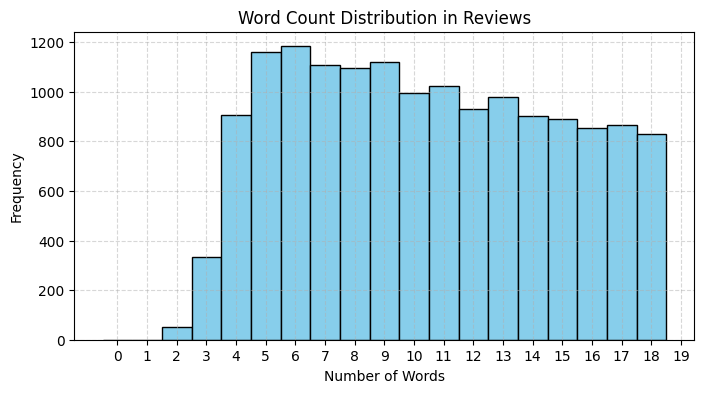

Filter:   0%|          | 0/43742 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1011 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1086 [00:00<?, ? examples/s]

/usr/local/lib/python3.11/dist-packages/transformers/convert_slow_tokenizer.py:564: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


Map:   0%|          | 0/43353 [00:00<?, ? examples/s]

Map:   0%|          | 0/1003 [00:00<?, ? examples/s]

... (16 outputs left out)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a9491f75fa9e2e971c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Your max_length is set to 30, but your input_length is only 10. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=5)
Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


'>>> Review: Cool for diy art & craft paper.'

'>>> True Summary: Very nice!'

'>>> Predicted Summary: <extra_id_0>.. <extra_id_36>. <extra_id_31>for diy crafts & craft paper.com.auловна.'


'<extra_id_0>.. <extra_id_36>. <extra_id_31>for diy crafts & craft paper.com.auловна.'

In [ ]:
# Load Dataset
import kagglehub
from datasets import load_dataset, concatenate_datasets, DatasetDict
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_scheduler, DataCollatorForSeq2Seq, pipeline

import nltk
nltk.download("punkt")
nltk.download("punkt_tab")

import evaluate
import rouge_score

import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW

import accelerate
from accelerate import Accelerator

from tqdm.auto import tqdm

import gradio as gr

import matplotlib.pyplot as plt
import numpy as np

from huggingface_hub import HfApi, create_repo, upload_folder, get_full_repo_name
from google.colab import userdata
import os

path = kagglehub.dataset_download("mexwell/amazon-reviews-multi")
ds = load_dataset("csv", data_files={
    "train": "/root/.cache/kagglehub/datasets/mexwell/amazon-reviews-multi/versions/1/train.csv",
    "validation": "/root/.cache/kagglehub/datasets/mexwell/amazon-reviews-multi/versions/1/validation.csv",
    "test": "/root/.cache/kagglehub/datasets/mexwell/amazon-reviews-multi/versions/1/test.csv"
    })

# Prepare the bilingual corpus of Deutsch and English
de_ds = ds.filter(lambda x: x["language"] == "de") # Deutsch
en_ds = ds.filter(lambda x: x["language"] == "en") # English

# Plot the distribution of product categories in the reviews of both languages
# Deutsch
de_ds.set_format("pandas")
de_df = de_ds["train"][:]
# print(de_df.head())
# print(de_df.product_category.value_counts())
de_ds.reset_format() # back to arrow

# English
en_ds.set_format("pandas")
en_df = en_ds["train"][:]
# print(en_df.head())
# print(en_df.product_category.value_counts())
en_ds.reset_format() # back to arrow

# Filter the reviews of just "home" product_category from both the languages
de_home_ds = de_ds.filter(lambda x: x["product_category"] == "home")
en_home_ds = en_ds.filter(lambda x: x["product_category"] == "home")

# Concatenate both the datasets
final_ds = DatasetDict()
for split in de_home_ds.keys():
    final_ds[split] = concatenate_datasets([de_home_ds[split], en_home_ds[split]], split=split)
    final_ds[split] = final_ds[split].shuffle(seed=42)

# Get the distribution of words in reviews
def word_distribution(examples):
    review_lengths = []
    for example in examples["review_body"]:
       review_lengths.append(len(example.split()))
    examples["review_length"] = review_lengths
    return examples

final_ds = final_ds.map(word_distribution, batched=True)

# Plot the distribution of words in reviews
def plot_word_distribution(lengths, title):
    plt.figure(figsize=(8, 4))
    plt.hist(lengths, bins=np.arange(0, 20) - 0.5, color="skyblue", edgecolor="black")
    plt.xlabel("Number of Words")
    plt.ylabel("Frequency")
    plt.xticks(range(0, 20))
    plt.title(f"Word Count Distribution in {title}")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

plot_word_distribution(final_ds["train"]["review_length"], "Reviews")

# Filter out the dataset with short reviews to make sure the model doesnt skew towards short summaries. Also remove review with no summaries, otherwise tokenizer fails
def filter_reviews(example):
    return (example["review_length"] > 3 and example["review_title"] and len(example["review_title"].strip()) > 0)
final_ds = final_ds.filter(filter_reviews)

# Utility function to show samples
def show_samples(ds, num_samples=3):
    for sample in range(num_samples):
        print(f"\n>>> Review: {ds[sample]['review_body']}")
        print(f">>> Summary: {ds[sample]['review_title']}")

# Preprocessing
checkpoint = "google/mt5-small"  # t5 model
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
max_input_seq_len = 512
max_target_length = 30

def preprocess(examples):
    inputs = tokenizer(examples["review_body"], max_length=max_input_seq_len, truncation=True)
    labels = tokenizer(examples["review_title"], max_length=max_target_length, truncation=True)
    inputs["labels"] = labels["input_ids"]
    return inputs

tokenized_ds = final_ds.map(preprocess, batched=True, remove_columns=final_ds["train"].column_names)

# Evaluation metric
metric = evaluate.load("rouge")

# lead-3 baseline
def three_sentence_summary(text):
    return "\n".join(nltk.sent_tokenize(text)[:3])

def evaluate_baseline(ds, metric):
    predictions = [three_sentence_summary(text) for text in ds["review_body"]]
    results = metric.compute(predictions=predictions, references=ds["review_title"])
    rouge_names = ["rouge1", "rouge2", "rougeL", "rougeLsum"]
    rouge_dict = dict((rn, round(results[rn] * 100, 2)) for rn in rouge_names)
    print(rouge_dict)

evaluate_baseline(final_ds["validation"], metric)

# Model
model = AutoModelForSeq2SeqLM.from_pretrained(checkpoint)

# Optimizer
optimizer = AdamW(model.parameters(), lr=2e-5)

# Saving
api = HfApi(token=userdata.get("HF_TOKEN"))
repo_name = "mt5_summarizer_amazon_reviews"
repo_id = get_full_repo_name(repo_name)
output_dir = "mt5_summarizer_amazon_reviews"
os.makedirs(output_dir, exist_ok=True)
os.environ["TOKENIZERS_PARALLELISM"] = "true"
try:
    create_repo(repo_id=repo_id, repo_type="model", private=False, token=api.token, exist_ok=True)
except Exception as E:
    print("Failed to create the repository")

# Data Collator and Data Loaders
collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model) # model needs to be passed to get decoder input ids

train_dl = DataLoader(tokenized_ds["train"], shuffle=True, batch_size=8, collate_fn=collator)
eval_dl = DataLoader(tokenized_ds["validation"], batch_size=8, collate_fn=collator)

# Accelerator
accelerator = Accelerator(mixed_precision="fp16")
model, optimizer, train_dl, eval_dl = accelerator.prepare(model, optimizer, train_dl, eval_dl)

# Scheduler
num_epochs = 1
num_steps_per_epoch = len(train_dl)
num_training_steps = num_steps_per_epoch * num_epochs
scheduler = get_scheduler("linear", optimizer=optimizer, num_training_steps=num_training_steps, num_warmup_steps=0)

# Post processing
def post_processing(preds, labels):
    def safe_tokenize(text):
        text = text.strip()
        return "\n".join(nltk.sent_tokenize(text))
    processed_preds = [safe_tokenize(pred) for pred in preds]
    processed_labels = [safe_tokenize(label) for label in labels]
    return processed_preds, processed_labels

# Training
progress_bar = tqdm(range(num_training_steps))

for epoch in range(num_epochs):
    model.train()
    for batch in train_dl:
        optimizer.zero_grad()
        outputs = model(**batch) # logits shape: (bs, max_seq_len, vocab_size) torch.Size([8, 15, 250112]))
        loss = outputs.loss
        accelerator.backward(loss)
        optimizer.step()
        scheduler.step()
        progress_bar.update(1)

    model.eval()
    for batch in eval_dl:
        generated_tokens =  accelerator.unwrap_model(model).generate(batch["input_ids"], attention_mask=batch["attention_mask"])  # (bs, max_target_length)
        generated_tokens = accelerator.pad_across_processes(generated_tokens, dim=1, pad_index=tokenizer.pad_token_id)
        labels = accelerator.pad_across_processes(batch["labels"], dim=1, pad_index=tokenizer.pad_token_id)
        generated_tokens = accelerator.gather(generated_tokens).cpu().numpy()
        labels = accelerator.gather(labels).cpu().numpy()

        labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
        if isinstance(generated_tokens, tuple):
            generated_tokens = generated_tokens[0]

        preds = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)
        references = tokenizer.batch_decode(labels, skip_special_tokens=True)
        preds, references = post_processing(preds, references)
        metric.add_batch(predictions=preds, references=references)
    results = metric.compute()
    final_results = {rn: round(results[rn] * 100, 2) for rn in results.keys()}
    print(f"Epoch: {epoch}\n {final_results}")
    accelerator.wait_for_everyone()
    unwrapped_model = accelerator.unwrap_model(model)
    if accelerator.is_main_process:
        unwrapped_model.save_pretrained(output_dir, save_function=accelerator.save)
        tokenizer.save_pretrained(output_dir)
        try:
            upload_folder(repo_id=repo_id, repo_type="model", folder_path=output_dir, commit_message=f"Training checkpoint at Epoch: {epoch}", token=api.token)
        except Exception as e:
            print(f"Unable to upload folder to Hugginface: {e}")

# Inference
summarizer = pipeline("summarization", model=repo_id)

def print_summary(idx):
    review = final_ds["test"][idx]["review_body"]
    title = final_ds["test"][idx]["review_title"]
    try:
        summary = summarizer(review, max_length=30, min_length=5, do_sample=False)[0]["summary_text"]
        print(f"'>>> Review: {review}'")
        print(f"\n'>>> True Summary: {title}'")
        print(f"\n'>>> Predicted Summary: {summary}'")
    except Exception as e:
        print(f"Error generating summary: {e}")
print_summary(100)

# Set up the Gradio interface
def summarize_review(review):
    if not review.strip():
        return "Please enter a valid review."
    try:
        result = summarizer(review, max_length=30, min_length=5, do_sample=False)[0]["summary_text"]
        return result
    except Exception as e:
        return f"Error generating summary: {e}"

demo = gr.Interface(
    fn=print_summary,
    inputs=gr.Textbox(label="Enter Amazon Review", lines=6, placeholder="Type or paste a product review here..."),
    outputs=gr.Textbox(label="Generated Summary"),
    title="Amazon Review Summarizer with mT5",
    description="This demo uses a fine-tuned mT5 model to summarize English and German Amazon product reviews. Trained on home-category reviews."
)
# Launch the demo
demo.launch()